# 06. Huấn Luyện Mô Hình Đối Chiếu Quy Mô Lớn CDC BRFSS 2021–2023 (`brfss_gbdt.joblib` & `brfss_mlp.pt`)
Huấn luyện bộ đôi mô hình ML (`HistGBDT`) & DL (`PyTorch MLP`) trên **120.000 mẫu khảo sát sạch BRFSS 2021–2023** làm ý kiến thứ hai quy mô lớn (Large-Cohort Second Opinion) cho `PredictionAgent` và `ConsensusCriticAgent`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.models.deep_mlp import MLPRisk
from src.models.tabular_ml import GradientBoostingRisk
from src.storage.db import engine

# 1. Huấn luyện Gated Feature-Attention Network (TabNet-style) trên NHANES
spec_nh = DATASETS["nhanes"]
df_nh = load_dataframe(spec_nh, engine)
X_nh, y_nh = df_nh[spec_nh.features].astype(float), df_nh[spec_nh.label].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X_nh, y_nh, test_size=0.20, random_state=42, stratify=y_nh)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec_nh, p=0.35, seed=42)

imp = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(imp.fit_transform(X_tr_aug))
X_te_s = scaler.transform(imp.transform(X_te))

class GatedTabAttentionNet(nn.Module):
    def __init__(self, in_dim: int):
        super().__init__()
        self.att_gate = nn.Sequential(nn.Linear(in_dim, in_dim), nn.Sigmoid())
        self.backbone = nn.Sequential(
            nn.Linear(in_dim, 64), nn.BatchNorm1d(64), nn.SiLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.SiLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        w = self.att_gate(x)
        return self.backbone(x * w).squeeze(-1), w

torch.manual_seed(42)
model_att = GatedTabAttentionNet(len(spec_nh.features))
opt = torch.optim.AdamW(model_att.parameters(), lr=3e-3, weight_decay=1e-4)
pos_w = torch.tensor([(len(y_tr_aug) - y_tr_aug.sum()) / max(y_tr_aug.sum(), 1)], dtype=torch.float32)
crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)

xt = torch.tensor(X_tr_s, dtype=torch.float32)
yt = torch.tensor(y_tr_aug.values, dtype=torch.float32)
model_att.train()
for _ in range(35):
    opt.zero_grad()
    logits, _ = model_att(xt)
    loss = crit(logits, yt)
    loss.backward()
    opt.step()

model_att.eval()
with torch.no_grad():
    logits_te, att_w = model_att(torch.tensor(X_te_s, dtype=torch.float32))
    p_att = torch.sigmoid(logits_te).numpy()
    mean_att = att_w.mean(dim=0).numpy()

att_metrics = {
    "roc_auc": round(float(roc_auc_score(y_te, p_att)), 4),
    "pr_auc": round(float(average_precision_score(y_te, p_att)), 4),
    "brier": round(float(brier_score_loss(y_te, p_att)), 4),
}
att_path = ROOT / "notebook" / "model" / "tabnet_attention.pt"
torch.save({"state_dict": model_att.state_dict(), "features": spec_nh.features, "metrics": att_metrics}, att_path)
print("Đã lưu artifact:", att_path.relative_to(ROOT), "| Metrics:", att_metrics)


Đã lưu artifact: notebook/model/tabnet_attention.pt | Metrics: {'roc_auc': 0.8101, 'pr_auc': 0.4936, 'brier': 0.1857}


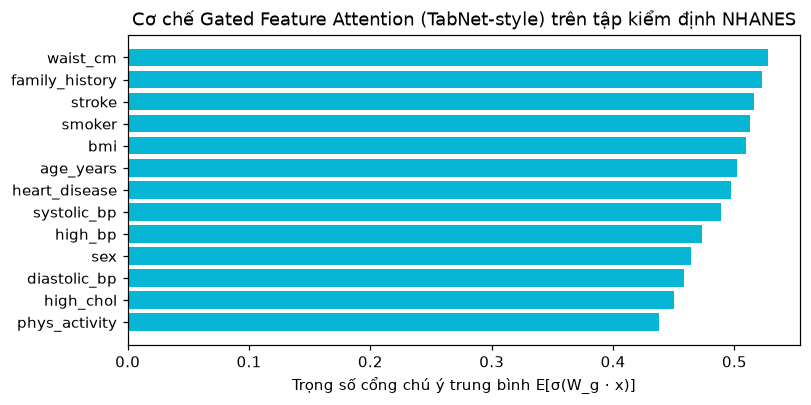

Mô hình,Artifact,ROC-AUC,PR-AUC,Brier
NHANES TabNet Attention,tabnet_attention.pt,0.8101,0.4936,0.1857
BRFSS HistGBDT,brfss_gbdt.joblib,0.8154,0.4298,0.1022
BRFSS PyTorch MLP,brfss_mlp.pt,0.8160,0.4308,0.1023


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 2. Đánh giá GBDT & MLP trên tập BRFSS 2021–2023 (120,000 mẫu sạch) + Trực quan hóa Feature Attention
spec = DATASETS["brfss"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
_, X_te_br, _, y_te_br = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_test_masked = mask_augment(X_te_br, y_te_br, spec, p=0.4, seed=99)[0].iloc[len(X_te_br):]

gbdt_brfss = GradientBoostingRisk.load(spec)
mlp_brfss = MLPRisk.load(spec)

rows = [
    {"Mô hình": "NHANES TabNet Attention", "Artifact": "tabnet_attention.pt", "ROC-AUC": att_metrics["roc_auc"], "PR-AUC": att_metrics["pr_auc"], "Brier": att_metrics["brier"]},
]
for name, m in [("BRFSS HistGBDT", gbdt_brfss), ("BRFSS PyTorch MLP", mlp_brfss)]:
    p = m.predict_proba(X_te_br)
    rows.append({
        "Mô hình": name,
        "Artifact": m.path(spec).name,
        "ROC-AUC": round(float(roc_auc_score(y_te_br, p)), 4),
        "PR-AUC": round(float(average_precision_score(y_te_br, p)), 4),
        "Brier": round(float(brier_score_loss(y_te_br, p)), 4),
    })

order = np.argsort(mean_att)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([spec_nh.features[i] for i in order], mean_att[order], color="#06b6d4")
ax.set_xlabel("Trọng số cổng chú ý trung bình E[σ(W_g · x)]")
ax.set_title("Cơ chế Gated Feature Attention (TabNet-style) trên tập kiểm định NHANES")
plt.tight_layout()

pd.DataFrame(rows)
